# COMP9517 Member A — Traditional Features + SVM

**Experimental Starting Point: Dataset v1.0 has been split, independently audited, and frozen. The experiments now begin from scratch.**

This is a self-contained experimental Notebook. Data checks, feature implementations, pilot experiments, full-scale training, ablation studies, metrics, figures, and decision records are all kept here.

Safety Rule: Do not read, display, or evaluate any test images before the final model configuration is frozen.

## 1. Experimental Procedure

```text
FFrozen Dataset v1.0
→ Data and Image Checks
→ Define Colour / LBP / HOG
→ 20-Class Pilot
→ 128 vs 224 HOG Image Size Ablation
→ 500-Class Descriptor Ablation
→ SVM C Ablation for the Best Descriptor
→ Freeze the Final Configuration
→ Final Test Evaluation
→ Confusion Matrix and Error Analysis
```

In [2]:
from pathlib import Path
from collections import Counter
import csv
import hashlib
import json
import math
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image
from skimage import exposure
from skimage.color import rgb2gray, rgb2hsv
from skimage.feature import hog, local_binary_pattern
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
METADATA_DIR = PROJECT_ROOT / "data_metadata"
DATA_ROOT = PROJECT_ROOT / "Dataset_v1.0_FROZEN"
WORK_DIR = PROJECT_ROOT / "experiment_workspace"
WORK_DIR.mkdir(exist_ok=True)

SEED = 9517
SVM_N_JOBS = 8
SVM_MAX_ITER = 1_000
SVM_TOL = 1e-3
SVM_AVERAGE = True
np.random.seed(SEED)
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_context("notebook")

assert (METADATA_DIR / "dataset_summary.json").is_file()
assert (DATA_ROOT / "train_mini").is_dir()
print("Project:", PROJECT_ROOT)
print("Experiment workspace:", WORK_DIR)
print("Test access: LOCKED")

Project: /Users/hope/Desktop/新南课程/9517/Project/9517GroupProject
Experiment workspace: /Users/hope/Desktop/新南课程/9517/Project/9517GroupProject/experiment_workspace
Test access: LOCKED


## 2. Confirm the Frozen Dataset

In [3]:
summary = json.loads((METADATA_DIR / "dataset_summary.json").read_text())
audit = json.loads((METADATA_DIR / "audit_report.json").read_text())
independent = json.loads((METADATA_DIR / "independent_audit_record.json").read_text())

status = pd.DataFrame({
    "Item": ["Version", "Status", "Seed", "Classes", "Train", "Validation", "Test", "Audit", "Auditor"],
    "Value": [summary["dataset_version"], summary["status"], summary["seed"], summary["num_classes"],
              summary["image_counts"]["train"], summary["image_counts"]["val"],
              summary["image_counts"]["test"], audit["status"], independent["auditor"]],
})
display(status.style.hide(axis="index"))
assert summary["dataset_version"] == "1.0" and summary["status"] == "FROZEN"
assert audit["status"] == "PASS"; print("Dataset audit: PASS")

Item,Value
Version,1.0
Status,FROZEN
Seed,9517
Classes,500
Train,20000
Validation,5000
Test,5000
Audit,PASS
Auditor,Member C


Dataset audit: PASS


,split,images,images_per_class
0,train,20000,40
1,validation,5000,10


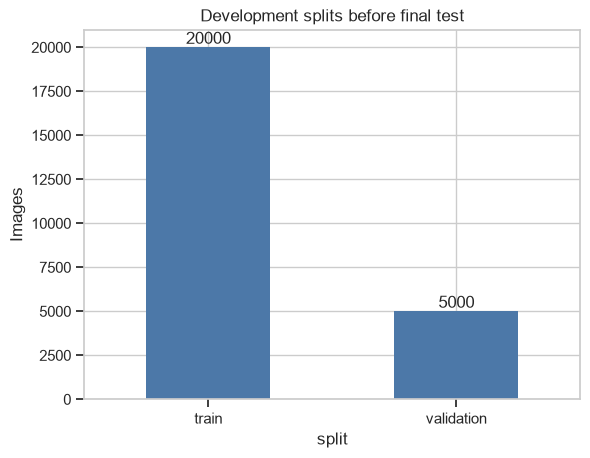

In [ ]:
# During the experimental phase, only the training and validation sets are loaded. test.csv is intentionally not loaded here.
train_df = pd.read_csv(METADATA_DIR / "train.csv")
val_df = pd.read_csv(METADATA_DIR / "val.csv")

split_table = pd.DataFrame({
    "split": ["train", "validation"],
    "images": [len(train_df), len(val_df)],
    "images_per_class": [train_df.groupby("class_index").size().iloc[0],
                         val_df.groupby("class_index").size().iloc[0]],
})
display(split_table)
ax = split_table.plot.bar(x="split", y="images", legend=False, color="#4c78a8")
ax.set_title("Development splits before final test")
ax.set_ylabel("Images")
ax.bar_label(ax.containers[0])
plt.xticks(rotation=0)
plt.show()

assert len(train_df) == 20_000 and len(val_df) == 5_000
assert set(train_df.groupby("class_index").size()) == {40}
assert set(val_df.groupby("class_index").size()) == {10}

## 3. view training images

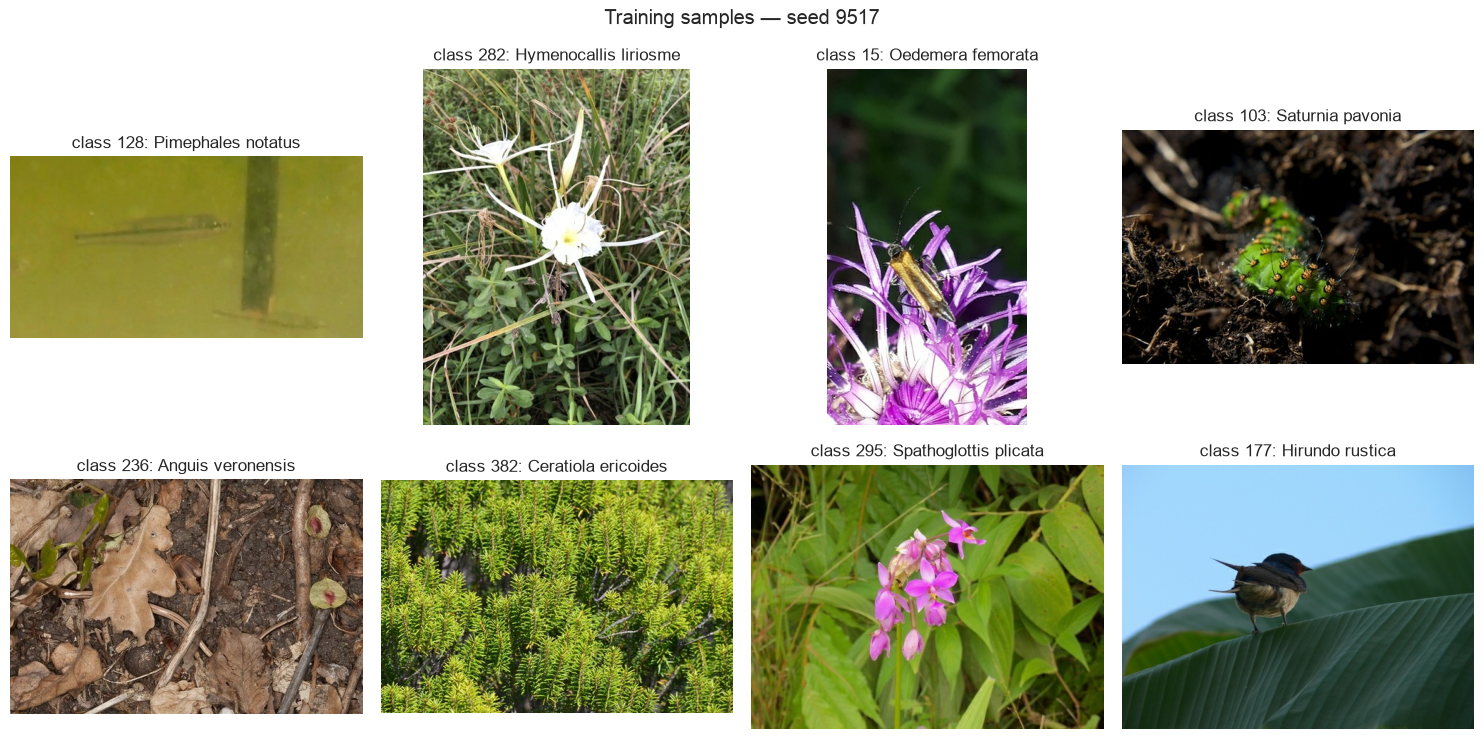

In [5]:
sample_rows = train_df.sample(8, random_state=SEED)
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for ax, (_, row) in zip(axes.flat, sample_rows.iterrows()):
    image = Image.open(DATA_ROOT / row.image_path).convert("RGB")
    ax.imshow(image)
    ax.set_title(f"class {row.class_index}: {row.species}")
    ax.axis("off")
plt.suptitle("Training samples — seed 9517")
plt.tight_layout()
plt.show()

## 4. Fix the Feature Definitions

- Colour: 16-bin HSV histogram + RGB mean/std/skewness, 57 dimensions.
- LBP: Uniform LBP with a 4×4 spatial grid, 160 dimensions.
- HOG: 9 orientations, 16×16 cells, and 2×2 blocks; 1,764 dimensions at 128 and 6,084 dimensions at 224.
- Combined: Concatenation of Colour, LBP, and HOG features.


In [6]:
def load_rgb(image_path, image_size):
    with Image.open(image_path) as image:
        return np.asarray(image.convert("RGB").resize(
            (image_size, image_size), Image.Resampling.BILINEAR), dtype=np.uint8)

def colour_features(rgb):
    hsv = rgb2hsv(rgb)
    parts = []
    for channel in range(3):
        hist, _ = np.histogram(hsv[:, :, channel], bins=16, range=(0, 1))
        parts.append(hist.astype(np.float32) / hist.sum())
    pixels = rgb.reshape(-1, 3).astype(np.float32) / 255.0
    mean = pixels.mean(axis=0)
    std = pixels.std(axis=0)
    skew = ((pixels - mean) ** 3).mean(axis=0) / np.maximum(std ** 3, 1e-8)
    return np.concatenate([*parts, mean, std, skew]).astype(np.float32)

def lbp_features(gray_uint8):
    lbp = local_binary_pattern(gray_uint8, P=8, R=1, method="uniform")
    parts = []
    for row_cell in np.array_split(lbp, 4, axis=0):
        for cell in np.array_split(row_cell, 4, axis=1):
            hist, _ = np.histogram(cell, bins=10, range=(0, 10))
            hist = hist.astype(np.float32)
            parts.append(hist / max(hist.sum(), 1.0))
    return np.concatenate(parts)

def hog_features(gray_float):
    return hog(gray_float, orientations=9, pixels_per_cell=(16, 16),
               cells_per_block=(2, 2), block_norm="L2-Hys",
               feature_vector=True).astype(np.float32)

def extract_blocks(image_path, image_size):
    rgb = load_rgb(image_path, image_size)
    gray = rgb2gray(rgb).astype(np.float32)
    gray_uint8 = np.rint(gray * 255).astype(np.uint8)
    return {"colour": colour_features(rgb), "lbp": lbp_features(gray_uint8),
            "hog": hog_features(gray)}

def select_descriptor(blocks, descriptor):
    if descriptor == "combined":
        return np.concatenate([blocks["colour"], blocks["lbp"], blocks["hog"]])
    return blocks[descriptor]

## 5. Feature Visualisation

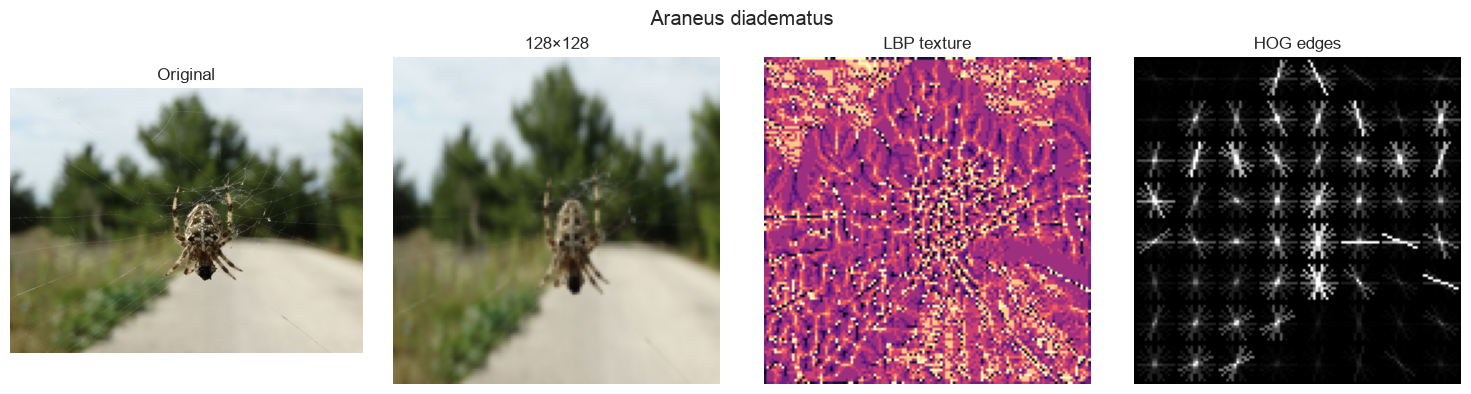

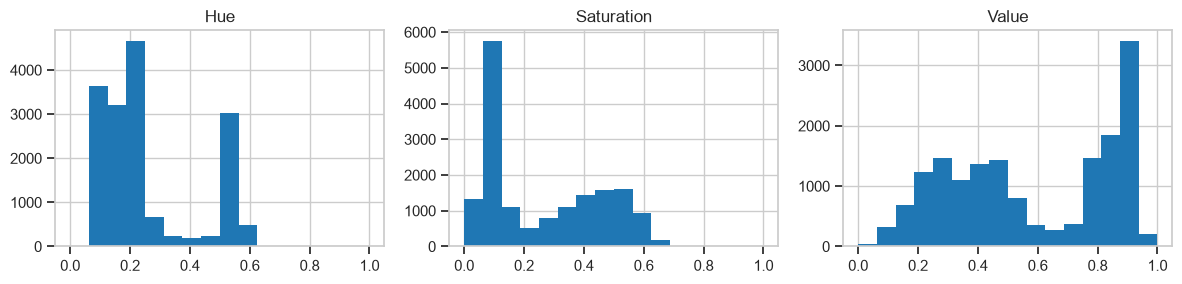

In [7]:
row = train_df.iloc[0]
original = Image.open(DATA_ROOT / row.image_path).convert("RGB")
rgb = np.asarray(original.resize((128, 128), Image.Resampling.BILINEAR))
gray = rgb2gray(rgb)
lbp_image = local_binary_pattern(np.rint(gray * 255).astype(np.uint8), 8, 1, method="uniform")
_, hog_image = hog(gray, orientations=9, pixels_per_cell=(16, 16),
                   cells_per_block=(2, 2), block_norm="L2-Hys", visualize=True)
hog_image = exposure.rescale_intensity(hog_image, in_range=(0, np.percentile(hog_image, 99)))

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, image, title, cmap in zip(
    axes, [original, rgb, lbp_image, hog_image],
    ["Original", "128×128", "LBP texture", "HOG edges"],
    [None, None, "magma", "gray"]):
    ax.imshow(image, cmap=cmap); ax.set_title(title); ax.axis("off")
plt.suptitle(row.species)
plt.tight_layout(); plt.show()

hsv = rgb2hsv(rgb)
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for channel, (name, ax) in enumerate(zip(["Hue", "Saturation", "Value"], axes)):
    ax.hist(hsv[:, :, channel].ravel(), bins=16, range=(0, 1))
    ax.set_title(name)
plt.tight_layout(); plt.show()

## 6. Shared Feature Extraction, Training, and Evaluation Functions

The classifier is a linear SVM with L2 regularisation and hinge loss. Since the one-vs-rest optimisation used by `LinearSVC` for 500 classes is not scalable on the local machine, the full-scale experiments use `SGDClassifier(loss="hinge")` to optimise the same type of linear SVM objective. The interpretable C parameter is retained using `alpha = 1 / (C × n_train)`. The settings `average=True`, `n_jobs=8`, and random seed 9517 are fixed.

In [8]:
def extract_dataframe(df, image_size, progress_every=500):
    dimensions = None
    blocks_out = None
    labels = df.class_index.to_numpy(dtype=np.int16)
    paths = df.image_path.astype(str).to_numpy()
    start = time.perf_counter()
    for i, relative_path in enumerate(paths):
        blocks = extract_blocks(DATA_ROOT / relative_path, image_size)
        if blocks_out is None:
            dimensions = {name: len(value) for name, value in blocks.items()}
            blocks_out = {name: np.empty((len(df), dim), np.float32)
                          for name, dim in dimensions.items()}
        for name in blocks_out:
            blocks_out[name][i] = blocks[name]
        if (i + 1) % progress_every == 0 or i + 1 == len(df):
            print(f"Extracted {i + 1}/{len(df)}")
    return blocks_out, labels, paths, time.perf_counter() - start

def descriptor_matrix(blocks, descriptor):
    if descriptor == "combined":
        return np.concatenate([blocks["colour"], blocks["lbp"], blocks["hog"]], axis=1)
    return blocks[descriptor]

def fit_and_evaluate(x_train, y_train, x_val, y_val, c_value=1.0):
    # SGDClassifier with hinge loss optimizes a linear SVM objective at dataset scale.
    # alpha = 1 / (C * N) matches the regularization scale of C in a linear SVM.
    alpha = 1.0 / (c_value * len(y_train))
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SGDClassifier(loss="hinge", penalty="l2", alpha=alpha,
                              max_iter=SVM_MAX_ITER, tol=SVM_TOL,
                              average=SVM_AVERAGE, n_jobs=SVM_N_JOBS,
                              random_state=SEED)),
    ])
    print(f"Training SGD linear SVM: samples={len(y_train)}, features={x_train.shape[1]}, "
          f"classes={len(np.unique(y_train))}, C={c_value:g}, alpha={alpha:.3g}")
    start = time.perf_counter()
    model.fit(x_train, y_train)
    fit_s = time.perf_counter() - start
    epochs = np.asarray(model.named_steps["svm"].n_iter_)
    print(f"Training complete: {fit_s:.1f}s, max_epochs={epochs.max()}")
    start = time.perf_counter()
    predicted = model.predict(x_val)
    scores = model.decision_function(x_val)
    predict_s = time.perf_counter() - start
    classes = model.named_steps["svm"].classes_
    top5 = classes[np.argsort(scores, axis=1)[:, ::-1][:, :5]]
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_val, predicted, labels=classes, average="macro", zero_division=0)
    metrics = {
        "top1_accuracy": float(np.mean(predicted == y_val)),
        "top5_accuracy": float(np.mean([truth in guesses for truth, guesses in zip(y_val, top5)])),
        "macro_precision": float(precision), "macro_recall": float(recall), "macro_f1": float(f1),
        "fit_seconds": fit_s, "predict_seconds": predict_s,
        "derived_alpha": alpha,
        "max_epochs": int(epochs.max()), "mean_epochs": float(epochs.mean()),
    }
    return model, predicted, top5, scores, metrics

def save_result(name, paths, y_true, y_pred, top5, scores, metrics, config, model):
    output = WORK_DIR / "results" / name
    output.mkdir(parents=True, exist_ok=True)
    predictions = pd.DataFrame({
        "image_path": paths, "true_class": y_true, "predicted_class": y_pred,
        "top5_classes": [json.dumps([int(x) for x in row]) for row in top5],
        "confidence": scores.max(axis=1),
    })
    predictions.to_csv(output / "predictions.csv", index=False)
    (output / "metrics.json").write_text(json.dumps(metrics, indent=2) + "\n")
    (output / "experiment_config.json").write_text(json.dumps(config, indent=2) + "\n")
    matrix = confusion_matrix(y_true, y_pred, labels=range(config["num_classes"]))
    pd.DataFrame(matrix).to_csv(output / "confusion_matrix.csv", index=False)
    joblib.dump(model, output / "model.joblib", compress=3)
    return output

## 7. Pilot (20 Classes, Pipeline Check Only)

First, run the Colour/LBP/HOG/Combined pilot experiments. The pilot results are not used to draw conclusions in the final report.

In [9]:
RUN_PILOT = False
PILOT_IMAGE_SIZE = 128
PILOT_DESCRIPTOR = "combined"  # colour / lbp / hog / combined
PILOT_CLASSES = 20

if RUN_PILOT:
    pilot_train = train_df[train_df.class_index < PILOT_CLASSES].reset_index(drop=True)
    pilot_val = val_df[val_df.class_index < PILOT_CLASSES].reset_index(drop=True)
    train_blocks, y_train, _, train_extract_s = extract_dataframe(pilot_train, PILOT_IMAGE_SIZE, 100)
    val_blocks, y_val, val_paths, val_extract_s = extract_dataframe(pilot_val, PILOT_IMAGE_SIZE, 100)
    x_train = descriptor_matrix(train_blocks, PILOT_DESCRIPTOR)
    x_val = descriptor_matrix(val_blocks, PILOT_DESCRIPTOR)
    model, predicted, top5, scores, metrics = fit_and_evaluate(x_train, y_train, x_val, y_val)
    config = {"stage": "pilot", "reported_result": False, "dataset_version": "1.0",
              "seed": SEED, "num_classes": PILOT_CLASSES, "image_size": PILOT_IMAGE_SIZE,
              "descriptor": PILOT_DESCRIPTOR, "C": 1.0,
              "classifier": "SGDClassifier", "loss": "hinge",
              "optimizer": "stochastic_gradient_descent",
              "alpha_formula": "1 / (C * n_train)",
              "n_jobs": SVM_N_JOBS, "average": SVM_AVERAGE,
              "max_iter": SVM_MAX_ITER, "tol": SVM_TOL,
              "train_feature_seconds": train_extract_s, "val_feature_seconds": val_extract_s}
    output = save_result(f"pilot_{PILOT_DESCRIPTOR}_{PILOT_IMAGE_SIZE}", val_paths, y_val,
                         predicted, top5, scores, metrics, config, model)
    display(pd.DataFrame([metrics])); print(output)
else:
    print("Pilot paused. Confirm settings, then set RUN_PILOT=True.")

Pilot paused. Confirm settings, then set RUN_PILOT=True.


## 8. Build the Full Train/Validation Feature Cache

In [10]:
def save_cache(size, split, blocks, labels, paths, extraction_seconds):
    cache_dir = WORK_DIR / "feature_cache" / f"size_{size}"
    cache_dir.mkdir(parents=True, exist_ok=True)
    path = cache_dir / f"{split}.npz"
    np.savez_compressed(path, colour=blocks["colour"], lbp=blocks["lbp"], hog=blocks["hog"],
                        labels=labels, image_paths=np.asarray(paths, dtype=str))
    record = {"dataset_version": "1.0", "seed": SEED, "image_size": size,
              "split": split, "samples": len(labels), "extraction_seconds": extraction_seconds,
              "dimensions": {k: v.shape[1] for k, v in blocks.items()}}
    (cache_dir / f"{split}_manifest.json").write_text(json.dumps(record, indent=2) + "\n")
    return path

BUILD_CACHE = False
CACHE_IMAGE_SIZE = 224  # Complete the 128×128 experiments before switching to 224×224.

if BUILD_CACHE:
    train_blocks, train_labels, train_paths, train_seconds = extract_dataframe(train_df, CACHE_IMAGE_SIZE)
    val_blocks, val_labels, val_paths, val_seconds = extract_dataframe(val_df, CACHE_IMAGE_SIZE)
    print(save_cache(CACHE_IMAGE_SIZE, "train", train_blocks, train_labels, train_paths, train_seconds))
    print(save_cache(CACHE_IMAGE_SIZE, "val", val_blocks, val_labels, val_paths, val_seconds))
else:
    print("Cache build paused. Confirm CACHE_IMAGE_SIZE, then set BUILD_CACHE=True.")

Cache build paused. Confirm CACHE_IMAGE_SIZE, then set BUILD_CACHE=True.


## 9. Run the Full 500-Class Validation Experiments Using Cached Features

In [11]:
def load_cache(size, split):
    path = WORK_DIR / "feature_cache" / f"size_{size}" / f"{split}.npz"
    with np.load(path, allow_pickle=False) as data:
        blocks = {name: data[name].copy() for name in ("colour", "lbp", "hog")}
        return blocks, data["labels"].astype(np.int64), data["image_paths"].copy()

def run_formal_validation(image_size, descriptor, c_value):
    train_blocks, y_train, _ = load_cache(image_size, "train")
    val_blocks, y_val, paths = load_cache(image_size, "val")
    x_train = descriptor_matrix(train_blocks, descriptor)
    x_val = descriptor_matrix(val_blocks, descriptor)
    model, predicted, top5, scores, metrics = fit_and_evaluate(
        x_train, y_train, x_val, y_val, c_value)
    config = {"stage": "formal_validation", "reported_result": True,
              "dataset_version": "1.0", "seed": SEED, "num_classes": 500,
              "image_size": image_size, "descriptor": descriptor, "C": c_value,
              "classifier": "SGDClassifier", "loss": "hinge",
              "optimizer": "stochastic_gradient_descent",
              "alpha": 1.0 / (c_value * len(y_train)),
              "alpha_formula": "1 / (C * n_train)",
              "n_jobs": SVM_N_JOBS, "average": SVM_AVERAGE,
              "max_iter": SVM_MAX_ITER, "tol": SVM_TOL}
    name = f"formal_{descriptor}_{image_size}_c{c_value:g}"
    output = save_result(name, paths, y_val, predicted, top5, scores, metrics, config, model)
    return output, metrics

## 10. Image Size Ablation: 128 vs 224 HOG

Fix HOG, SVM, and C=1.0, and change only the image size. Run one configuration at a time.

In [12]:
RUN_SIZE_ABLATION = False
SIZE_TO_RUN = 224  # 完成后改为224

if RUN_SIZE_ABLATION:
    output, metrics = run_formal_validation(SIZE_TO_RUN, "hog", 1.0)
    display(pd.DataFrame([metrics])); print(output)
else:
    print("Size ablation paused.")

Size ablation paused.


## 11. Descriptor Ablation

Set `FINAL_IMAGE_SIZE` based on the image size ablation results, then fix C=1.0 and run the four descriptors one at a time.

In [13]:
RUN_DESCRIPTOR_ABLATION = False
FINAL_IMAGE_SIZE = 128
DESCRIPTOR_TO_RUN = "combined"  # colour / lbp / hog / combined

if FINAL_IMAGE_SIZE not in (128, 224):
    print("Locked: decide FINAL_IMAGE_SIZE first.")
elif RUN_DESCRIPTOR_ABLATION:
    output, metrics = run_formal_validation(FINAL_IMAGE_SIZE, DESCRIPTOR_TO_RUN, 1.0)
    display(pd.DataFrame([metrics])); print(output)
else:
    print("Descriptor ablation paused.")

Descriptor ablation paused.


## 12. SVM C Ablation

Set the best image size and descriptor based on the descriptor ablation results, then evaluate `C ∈ {0.01, 0.1, 1, 10}`. To accommodate the 500-class scale, use the hinge-loss `SGDClassifier` to optimise the linear SVM objective, with the fixed conversion `alpha = 1 / (C × n_train)`.

In [14]:
RUN_C_ABLATION = False
BEST_IMAGE_SIZE = 128
BEST_DESCRIPTOR = "combined"
C_TO_RUN = 10

if BEST_IMAGE_SIZE not in (128, 224) or BEST_DESCRIPTOR not in ("colour", "lbp", "hog", "combined"):
    print("Locked: decide BEST_IMAGE_SIZE and BEST_DESCRIPTOR first.")
elif RUN_C_ABLATION:
    output, metrics = run_formal_validation(BEST_IMAGE_SIZE, BEST_DESCRIPTOR, C_TO_RUN)
    display(pd.DataFrame([metrics])); print(output)
else:
    print("C ablation paused.")

C ablation paused.


## 13. Automatically Summarise the Validation Results

,experiment,stage,reported_result,dataset_version,seed,num_classes,image_size,descriptor,C,classifier,...,macro_precision,macro_recall,macro_f1,fit_seconds,predict_seconds,derived_alpha,max_epochs,mean_epochs,train_feature_seconds,val_feature_seconds
3,formal_combined_128_c1,formal_validation,True,1.0,9517,500,128,combined,1.00,SGDClassifier,...,0.051349,0.0480,0.042500,289.106984,0.027471,0.000050,175.0,175.0,NaN,NaN
2,formal_combined_128_c0.1,formal_validation,True,1.0,9517,500,128,combined,0.10,SGDClassifier,...,0.035114,0.0406,0.027423,72.146180,0.028183,0.000500,48.0,48.0,NaN,NaN
4,formal_combined_128_c10,formal_validation,True,1.0,9517,500,128,combined,10.00,SGDClassifier,...,0.043400,0.0390,0.038916,258.417496,0.028436,0.000005,474.0,474.0,NaN,NaN
1,formal_combined_128_c0.01,formal_validation,True,1.0,9517,500,128,combined,0.01,SGDClassifier,...,0.027701,0.0348,0.017832,29.777569,0.028606,0.005000,19.0,19.0,NaN,NaN
5,formal_hog_128_c1,formal_validation,True,1.0,9517,500,128,hog,1.00,SGDClassifier,...,0.027156,0.0284,0.024813,265.074008,0.023713,0.000050,183.0,183.0,NaN,NaN
7,formal_lbp_128_c1,formal_validation,True,1.0,9517,500,128,lbp,1.00,SGDClassifier,...,0.024684,0.0250,0.017762,19.903449,0.005084,0.000050,128.0,128.0,NaN,NaN
6,formal_hog_224_c1,formal_validation,True,1.0,9517,500,224,hog,1.00,SGDClassifier,...,0.023927,0.0232,0.020833,807.271399,0.077527,0.000050,188.0,188.0,NaN,NaN
0,formal_colour_128_c1,formal_validation,True,1.0,9517,500,128,colour,1.00,SGDClassifier,...,0.025821,0.0216,0.016212,8.528338,0.003954,0.000050,98.0,98.0,NaN,NaN


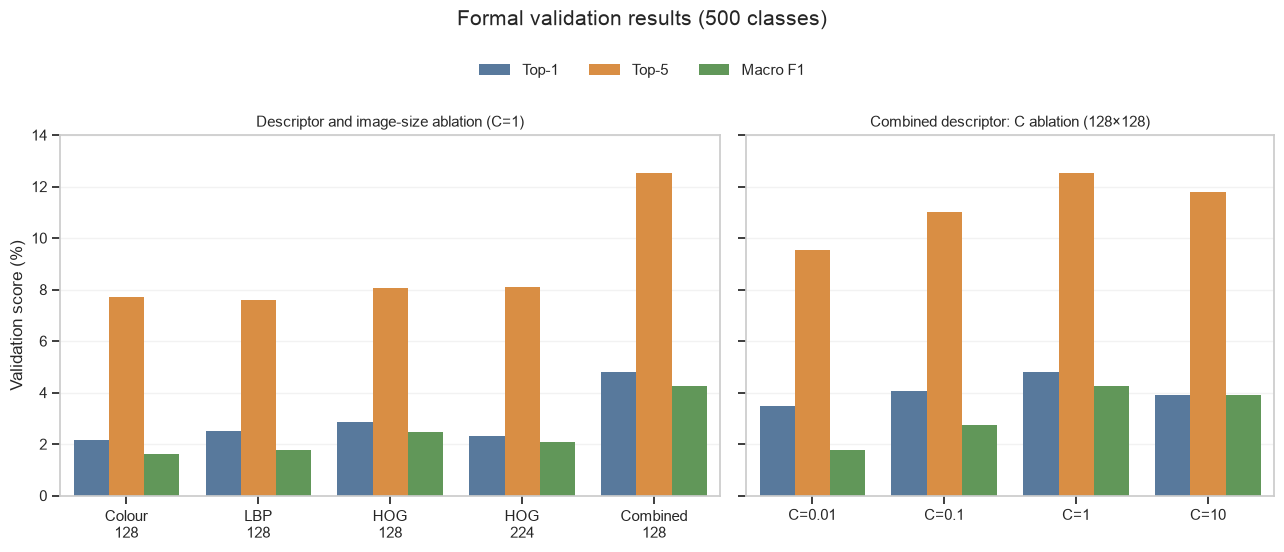

In [15]:
result_rows = []
results_root = WORK_DIR / "results"
for metrics_path in sorted(results_root.glob("*/metrics.json")) if results_root.exists() else []:
    config = json.loads((metrics_path.parent / "experiment_config.json").read_text())
    metrics = json.loads(metrics_path.read_text())
    result_rows.append({"experiment": metrics_path.parent.name, **config, **metrics})
results = pd.DataFrame(result_rows)
formal_results = (results[results["reported_result"].fillna(False).astype(bool)].copy()
                  if not results.empty and "reported_result" in results else pd.DataFrame())
if formal_results.empty:
    print("No experiment results yet — this is the clean starting state.")
else:
    formal_results = formal_results.sort_values("top1_accuracy", ascending=False)
    formal_results.to_csv(results_root / "formal_validation_summary.csv", index=False)
    display(formal_results)
    metric_columns = ["top1_accuracy", "top5_accuracy", "macro_f1"]
    metric_labels = {"top1_accuracy": "Top-1", "top5_accuracy": "Top-5",
                     "macro_f1": "Macro F1"}
    palette = {"Top-1": "#4C78A8", "Top-5": "#F28E2B",
               "Macro F1": "#59A14F"}
    method_order = ["Colour\n128", "LBP\n128", "HOG\n128",
                    "HOG\n224", "Combined\n128"]
    methods = formal_results[formal_results["C"].eq(1.0)].copy()
    descriptor_labels = {"colour": "Colour", "lbp": "LBP",
                         "hog": "HOG", "combined": "Combined"}
    methods["label"] = (methods["descriptor"].map(descriptor_labels) + "\n" +
                        methods["image_size"].astype(int).astype(str))
    c_results = formal_results[(formal_results["descriptor"].eq("combined")) &
                               (formal_results["image_size"].eq(128))].copy()
    c_results["label"] = c_results["C"].map(lambda value: f"C={value:g}")
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True,
                             gridspec_kw={"width_ratios": [1.25, 1]})
    for ax, frame, order, title in [
        (axes[0], methods, method_order, "Descriptor and image-size ablation (C=1)"),
        (axes[1], c_results, ["C=0.01", "C=0.1", "C=1", "C=10"],
         "Combined descriptor: C ablation (128×128)")]:
        tidy = frame.melt(id_vars="label", value_vars=metric_columns,
                          var_name="metric", value_name="score")
        tidy["metric"] = tidy["metric"].map(metric_labels)
        tidy["score_percent"] = tidy["score"] * 100
        sns.barplot(data=tidy, x="label", y="score_percent", hue="metric",
                    order=order, hue_order=list(palette), palette=palette, ax=ax)
        ax.set_title(title, fontsize=11); ax.set_xlabel("")
        ax.grid(axis="y", alpha=0.25); ax.legend_.remove()
    axes[0].set_ylabel("Validation score (%)"); axes[1].set_ylabel("")
    axes[0].set_ylim(0, 14)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False,
               bbox_to_anchor=(0.5, 1.02))
    fig.suptitle("Formal validation results (500 classes)", y=1.10, fontsize=15)
    fig.tight_layout()
    fig.savefig(results_root / "formal_validation_comparison.png", dpi=200,
                bbox_inches="tight")
    plt.show()

## 14. Confusion Matrix and Most Frequently Confused Species

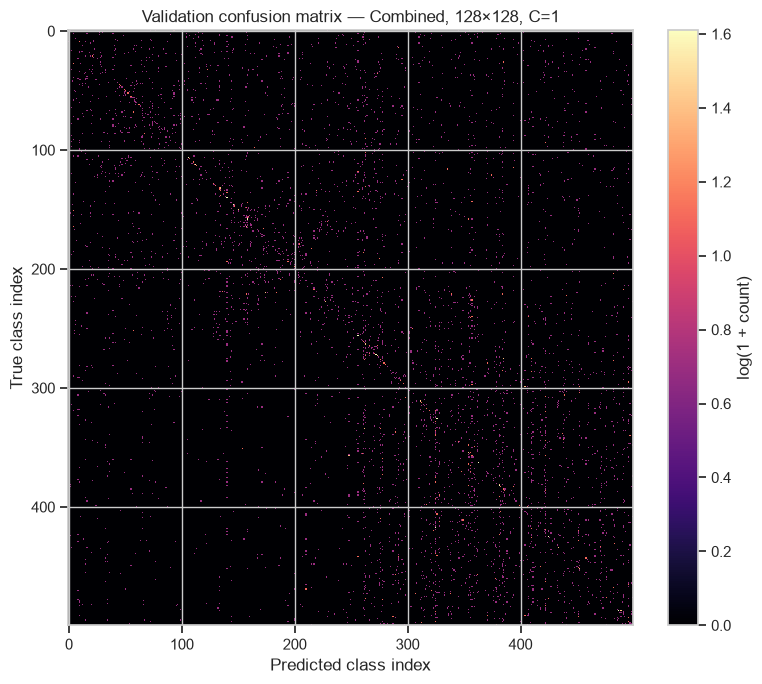

,true_class,true_species,predicted_class,predicted_species,count
3518,382,Ceratiola ericoides,381,Calluna vulgaris,4
3836,417,Vitex agnus-castus,325,Eupatorium altissimum,4
2551,275,Rhizomnium glabrescens,385,Gaultheria antipoda,3
3291,357,Escobaria vivipara,248,Sistrurus catenatus,3
1237,132,Chaetodon capistratus,134,Parupeneus spilurus,3
4479,487,Sequoiadendron giganteum,489,Taxodium mucronatum,3
2043,220,Oreotragus oreotragus,174,Pyrrhocorax graculus,3
2766,299,Lilium bulbiferum,404,Morella californica,3
1519,164,Numenius madagascariensis,157,Pluvialis dominica,3
3084,334,Packera tampicana,262,Teloschistes flavicans,3


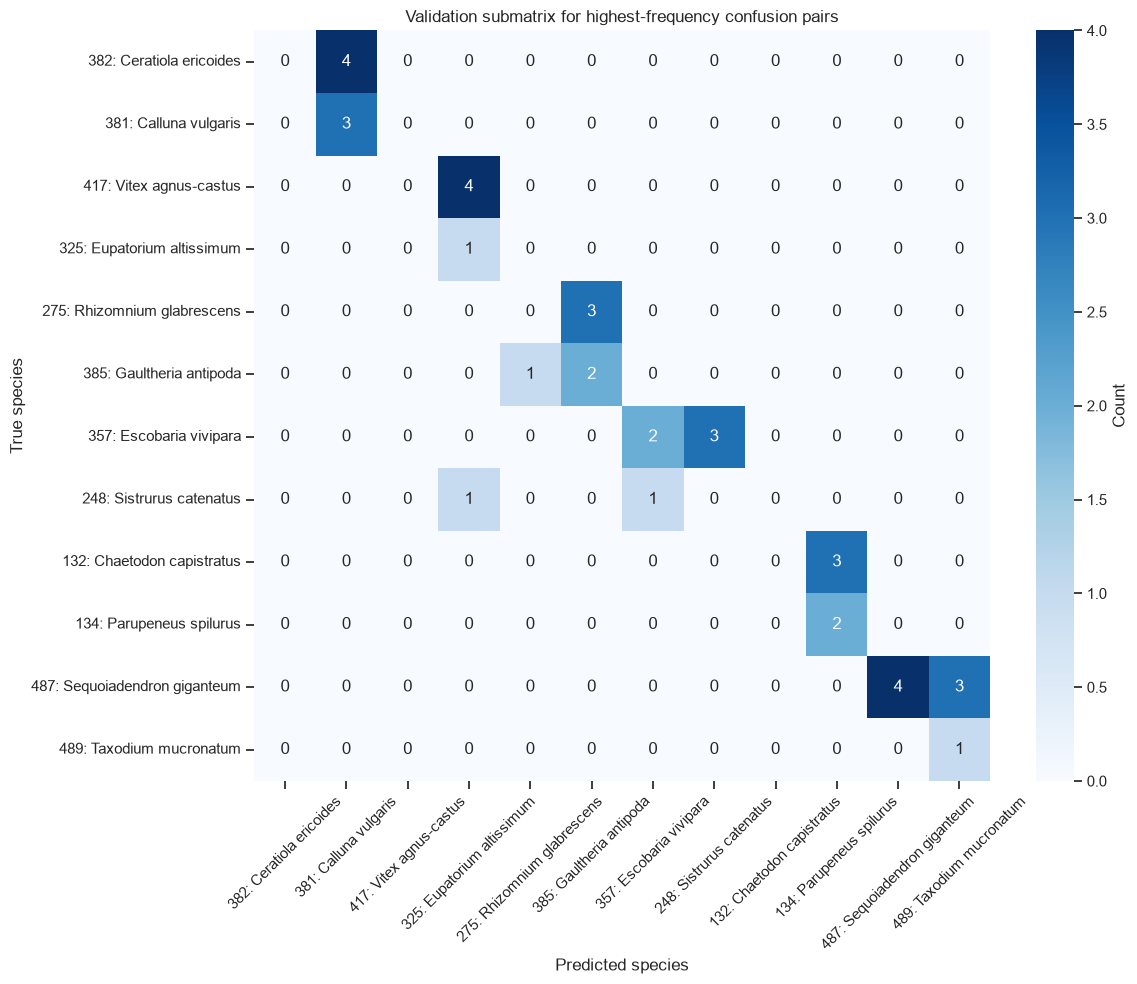

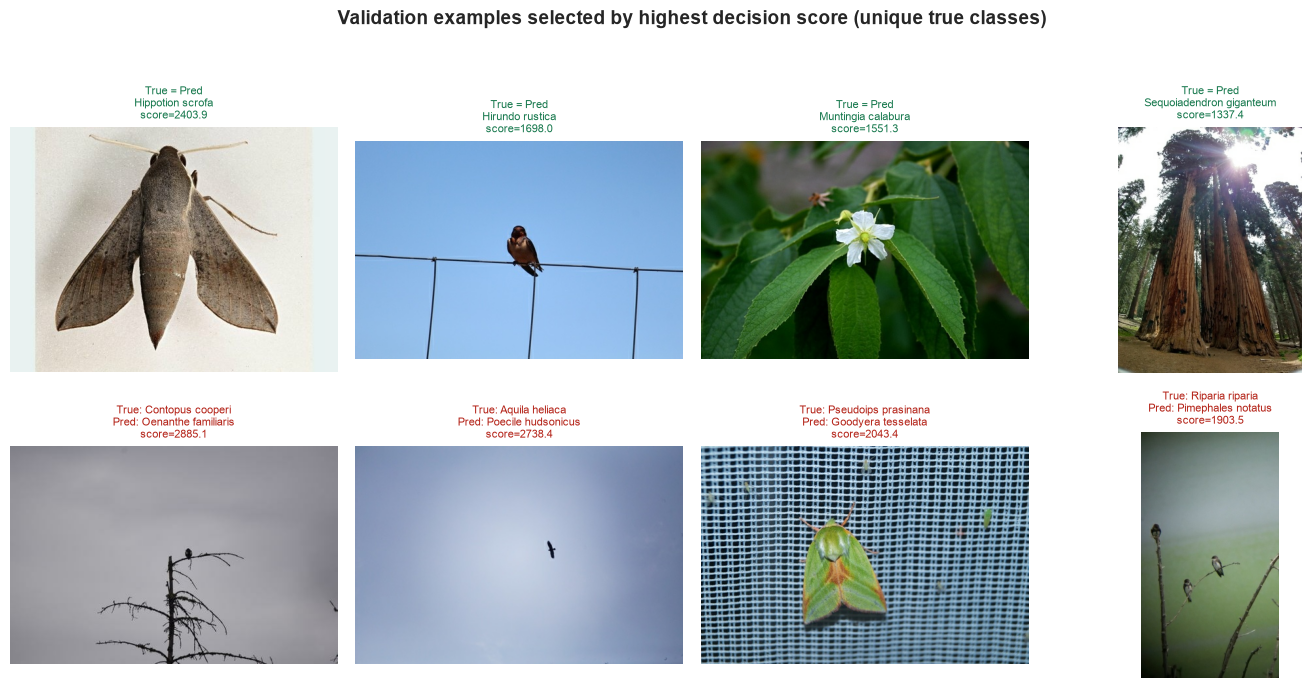

,case_type,true_class,true_species,predicted_class,predicted_species,confidence,image_path
0,correct,106,Hippotion scrofa,106,Hippotion scrofa,2403.9170,train_mini/02198_Animalia_Arthropoda_Insecta_L...
1,correct,177,Hirundo rustica,177,Hirundo rustica,1697.9951,train_mini/03849_Animalia_Chordata_Aves_Passer...
2,correct,445,Muntingia calabura,445,Muntingia calabura,1551.3193,train_mini/08987_Plantae_Tracheophyta_Magnolio...
3,correct,487,Sequoiadendron giganteum,487,Sequoiadendron giganteum,1337.3789,train_mini/09791_Plantae_Tracheophyta_Pinopsid...
4,incorrect,203,Contopus cooperi,185,Oenanthe familiaris,2885.0580,train_mini/04293_Animalia_Chordata_Aves_Passer...
5,incorrect,146,Aquila heliaca,186,Poecile hudsonicus,2738.4140,train_mini/03120_Animalia_Chordata_Aves_Accipi...
6,incorrect,84,Pseudoips prasinana,292,Goodyera tesselata,2043.4097,train_mini/01729_Animalia_Arthropoda_Insecta_L...
7,incorrect,178,Riparia riparia,128,Pimephales notatus,1903.4790,train_mini/03859_Animalia_Chordata_Aves_Passer...


In [16]:
FORMAL_RESULT_TO_ANALYSE = "formal_combined_128_c1"

if FORMAL_RESULT_TO_ANALYSE is None:
    print("Choose a completed formal validation result first.")
else:
    folder = WORK_DIR / "results" / FORMAL_RESULT_TO_ANALYSE
    predictions = pd.read_csv(folder / "predictions.csv")
    taxonomy = pd.read_csv(METADATA_DIR / "taxonomy.csv").set_index("class_index")
    matrix = confusion_matrix(predictions.true_class, predictions.predicted_class, labels=range(500))

    # Log scaling keeps the sparse 500-class structure visible without changing counts.
    fig, ax = plt.subplots(figsize=(8, 7))
    image = ax.imshow(np.log1p(matrix), cmap="magma", aspect="auto",
                      interpolation="nearest")
    ax.set_title("Validation confusion matrix — Combined, 128×128, C=1")
    ax.set_xlabel("Predicted class index"); ax.set_ylabel("True class index")
    fig.colorbar(image, ax=ax, label="log(1 + count)")
    fig.tight_layout(); fig.savefig(folder / "overall_confusion_matrix.png",
                                    dpi=200, bbox_inches="tight")
    plt.show()

    errors = predictions[predictions.true_class != predictions.predicted_class]
    pairs = (errors.groupby(["true_class", "predicted_class"]).size()
             .reset_index(name="count").sort_values("count", ascending=False))
    pairs["true_species"] = pairs["true_class"].map(taxonomy["species"])
    pairs["predicted_species"] = pairs["predicted_class"].map(taxonomy["species"])
    pairs["true_common_name"] = pairs["true_class"].map(taxonomy["common_name"])
    pairs["predicted_common_name"] = pairs["predicted_class"].map(taxonomy["common_name"])
    pairs.to_csv(folder / "top_confusion_pairs.csv", index=False)
    display(pairs[["true_class", "true_species", "predicted_class",
                   "predicted_species", "count"]].head(15))

    # Select up to 12 classes from the most frequent directed confusion pairs.
    selected_classes = []
    for row in pairs.itertuples(index=False):
        for class_index in (row.true_class, row.predicted_class):
            if class_index not in selected_classes:
                selected_classes.append(int(class_index))
        if len(selected_classes) >= 12:
            break
    selected_classes = selected_classes[:12]
    subset = matrix[np.ix_(selected_classes, selected_classes)]
    subset_labels = [f"{index}: {taxonomy.loc[index, 'species']}"
                     for index in selected_classes]
    fig, ax = plt.subplots(figsize=(12, 10))
    sns.heatmap(subset, annot=True, fmt="d", cmap="Blues", cbar_kws={"label": "Count"},
                xticklabels=subset_labels, yticklabels=subset_labels, ax=ax)
    ax.set_title("Validation submatrix for highest-frequency confusion pairs")
    ax.set_xlabel("Predicted species"); ax.set_ylabel("True species")
    ax.tick_params(axis="x", rotation=45); ax.tick_params(axis="y", rotation=0)
    fig.tight_layout(); fig.savefig(folder / "top_confusion_submatrix.png",
                                    dpi=200, bbox_inches="tight")
    plt.show()

    # Deterministic qualitative examples: highest model scores, with unique true classes.
    # These are validation examples only; test remains locked.
    correct = predictions[predictions.true_class == predictions.predicted_class]
    incorrect = predictions[predictions.true_class != predictions.predicted_class]
    correct_cases = (correct.sort_values(["confidence", "image_path"], ascending=[False, True])
                     .drop_duplicates("true_class").head(4).copy())
    incorrect_cases = (incorrect.sort_values(["confidence", "image_path"], ascending=[False, True])
                       .drop_duplicates("true_class").head(4).copy())
    correct_cases["case_type"] = "correct"
    incorrect_cases["case_type"] = "incorrect"
    cases = pd.concat([correct_cases, incorrect_cases], ignore_index=True)
    cases["true_species"] = cases["true_class"].map(taxonomy["species"])
    cases["predicted_species"] = cases["predicted_class"].map(taxonomy["species"])
    cases.to_csv(folder / "validation_case_examples.csv", index=False)

    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for row_index, (case_type, selected) in enumerate(
            [("Correct", correct_cases), ("Incorrect", incorrect_cases)]):
        for column_index, case in enumerate(selected.itertuples(index=False)):
            ax = axes[row_index, column_index]
            with Image.open(DATA_ROOT / case.image_path) as image_file:
                ax.imshow(image_file.convert("RGB"))
            true_species = taxonomy.loc[case.true_class, "species"]
            predicted_species = taxonomy.loc[case.predicted_class, "species"]
            if case_type == "Correct":
                title = f"True = Pred\n{true_species}\nscore={case.confidence:.1f}"
                colour = "#18794e"
            else:
                title = (f"True: {true_species}\nPred: {predicted_species}"
                         f"\nscore={case.confidence:.1f}")
                colour = "#b42318"
            ax.set_title(title, fontsize=8, color=colour)
            ax.axis("off")
        axes[row_index, 0].set_ylabel(case_type, fontsize=12, fontweight="bold",
                                      color="#18794e" if row_index == 0 else "#b42318")
    fig.suptitle("Validation examples selected by highest decision score (unique true classes)",
                 fontsize=14, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.95])
    fig.savefig(folder / "validation_success_failure_cases.png",
                dpi=200, bbox_inches="tight")
    plt.show()
    display(cases[["case_type", "true_class", "true_species", "predicted_class",
                   "predicted_species", "confidence", "image_path"]])

### 14.1 Validation Error Analysis and Report Conclusion

**Quantitative Results**

- The final candidate configuration (128×128, Combined, C=1) correctly classified 240 and misclassified 4,760 of the 5,000 validation images, resulting in a Top-1 accuracy of 4.80%. The model produced predictions across 472 of the 500 classes.
- Frequent confusions included visually or contextually similar species, such as *Ceratiola ericoides* → *Calluna vulgaris* (4 times), *Sequoiadendron giganteum* → *Taxodium mucronatum* (3 times), and *Chaetodon capistratus* → *Parupeneus spilurus* (3 times).
- Cross-taxon errors also occurred, such as cactus → rattlesnake and mammal → bird. This indicates that the current handcrafted features cannot reliably represent high-level object semantics.

**Qualitative Analysis of the Example Images**

- Correctly classified examples usually contain a large main subject with clear shape, colour, or texture information. This allows HOG, Colour, and LBP to capture discriminative features.
- In many high-scoring misclassified examples, the subject is small or distant, or the background occupies most of the image. The model may therefore match background textures, such as sky, branches, vegetation, or grids, rather than the target object itself.
- Some incorrect predictions have higher decision scores than correctly classified examples. Therefore, the decision score is used only to rank classes and should not be interpreted as a calibrated probability of correctness.
- The example images are selected using a fixed rule: only one image is retained for each ground-truth class, and the images are ranked by decision score in descending order. This selection is intended to analyse the model’s most confident successes and failures and does not represent the natural distribution of all validation samples.

**Conclusion:** The Combined handcrafted descriptor provides an interpretable traditional machine-learning baseline. However, its low Top-1 accuracy, Top-5 accuracy, and Macro F1 indicate that stronger semantic representations from the deep-learning methods developed by other team members are needed for the final system.

## 15. Final Test Evaluation

The final configuration was frozen on 2026-07-23 based on the validation results: `128×128 + Combined + C=1`. The frozen configuration is stored in `experiment_workspace/FINAL_MODEL_CONFIG.json`.

Member A has explicitly confirmed that the test set may be unlocked. This cell only loads the frozen model and performs the final evaluation once, without retraining. After successful completion, the test status is automatically changed to `CONSUMED_LOCKED`. **The final test results must not be used for further hyperparameter tuning.**

In [ ]:
RUN_FINAL_TEST = False  # The single final evaluation has been completed. Keep this set to `False` to prevent repeated evaluation.

if not RUN_FINAL_TEST:
    print("Final test already completed; see the frozen results below.")
else:
    freeze_path = WORK_DIR / "FINAL_MODEL_CONFIG.json"
    freeze = json.loads(freeze_path.read_text())
    assert freeze["status"] == "FROZEN" and freeze["tuning_closed"] is True
    assert freeze["test_access"] == "UNLOCKED_FOR_SINGLE_EVALUATION"
    assert freeze["test_evaluations_completed"] == 0

    source_folder = PROJECT_ROOT / freeze["source_result_directory"]
    model_path = source_folder / "model.joblib"
    actual_model_sha = hashlib.sha256(model_path.read_bytes()).hexdigest()
    assert actual_model_sha == freeze["sha256"]["model.joblib"]

    test_df = pd.read_csv(METADATA_DIR / "test.csv")
    test_counts = test_df.groupby("class_index").size()
    assert len(test_df) == 5_000 and test_df.class_index.nunique() == 500
    assert test_counts.min() == 10 and test_counts.max() == 10

    test_blocks, y_test, test_paths, test_extract_s = extract_dataframe(
        test_df, freeze["final_configuration"]["image_size"], progress_every=250)
    x_test = descriptor_matrix(test_blocks, freeze["final_configuration"]["descriptor"])
    frozen_model = joblib.load(model_path)

    start = time.perf_counter()
    test_predicted = frozen_model.predict(x_test)
    test_scores = frozen_model.decision_function(x_test)
    test_predict_s = time.perf_counter() - start
    model_classes = frozen_model.named_steps["svm"].classes_
    test_top5 = model_classes[np.argsort(test_scores, axis=1)[:, ::-1][:, :5]]
    test_precision, test_recall, test_f1, _ = precision_recall_fscore_support(
        y_test, test_predicted, labels=range(500), average="macro", zero_division=0)
    test_metrics = {
        "num_images": int(len(y_test)),
        "top1_accuracy": float(np.mean(test_predicted == y_test)),
        "top5_accuracy": float(np.mean([
            truth in guesses for truth, guesses in zip(y_test, test_top5)])),
        "macro_precision": float(test_precision),
        "macro_recall": float(test_recall),
        "macro_f1": float(test_f1),
        "feature_extraction_seconds": float(test_extract_s),
        "predict_seconds": float(test_predict_s),
    }

    test_output = WORK_DIR / "results" / "final_test_combined_128_c1"
    assert not test_output.exists(), "Final test output already exists; repeated evaluation blocked."
    test_output.mkdir(parents=True)
    test_predictions = pd.DataFrame({
        "image_path": test_paths,
        "true_class": y_test,
        "predicted_class": test_predicted,
        "top5_classes": [json.dumps([int(x) for x in row]) for row in test_top5],
        "confidence": test_scores.max(axis=1),
    })
    test_predictions.to_csv(test_output / "predictions.csv", index=False)
    (test_output / "metrics.json").write_text(json.dumps(test_metrics, indent=2) + "\n")
    test_matrix = confusion_matrix(y_test, test_predicted, labels=range(500))
    pd.DataFrame(test_matrix).to_csv(test_output / "confusion_matrix.csv", index=False)

    fig, ax = plt.subplots(figsize=(8, 7))
    test_image = ax.imshow(np.log1p(test_matrix), cmap="magma", aspect="auto",
                           interpolation="nearest")
    ax.set_title("Final test confusion matrix — frozen Member A model")
    ax.set_xlabel("Predicted class index"); ax.set_ylabel("True class index")
    fig.colorbar(test_image, ax=ax, label="log(1 + count)")
    fig.tight_layout()
    fig.savefig(test_output / "test_confusion_matrix.png", dpi=200, bbox_inches="tight")
    plt.show()

    freeze["test_access"] = "CONSUMED_LOCKED"
    freeze["test_evaluations_completed"] = 1
    freeze["test_result_directory"] = str(test_output.relative_to(PROJECT_ROOT))
    freeze["test_metrics"] = test_metrics
    freeze["post_test_tuning_allowed"] = False
    freeze_path.write_text(json.dumps(freeze, indent=2) + "\n")

    display(pd.DataFrame([test_metrics]))
    print(f"Final test complete and re-locked: {test_output}")

### 15.1 Final Test Results (Relocked)

| Metric | Validation | Final Test | Difference (Test − Validation) |
|---|---:|---:|---:|
| Top-1 Accuracy | 4.80% | **4.48%** (224/5,000) | −0.32 pp |
| Top-5 Accuracy | 12.54% | **12.16%** (608/5,000) | −0.38 pp |
| Macro Precision | 5.13% | **4.90%** | −0.23 pp |
| Macro Recall | 4.80% | **4.48%** | −0.32 pp |
| Macro F1 | 4.25% | **3.99%** | −0.26 pp |

- Test feature extraction time: 24.97 seconds. Frozen-model prediction time: 0.029 seconds for 5,000 images, excluding disk loading and feature extraction.
- The validation and test metrics are similar, with no unusually large performance drop. This indicates that the traditional baseline selected using the validation set transfers consistently to the independent test split.
- These results were obtained from the single permitted test evaluation. The test status is now `CONSUMED_LOCKED`, and the model parameters must not be modified based on the test results.

Displaying saved image: /Users/hope/Desktop/新南课程/9517/Project/9517GroupProject/experiment_workspace/results/final_test_combined_128_c1/test_confusion_matrix.png


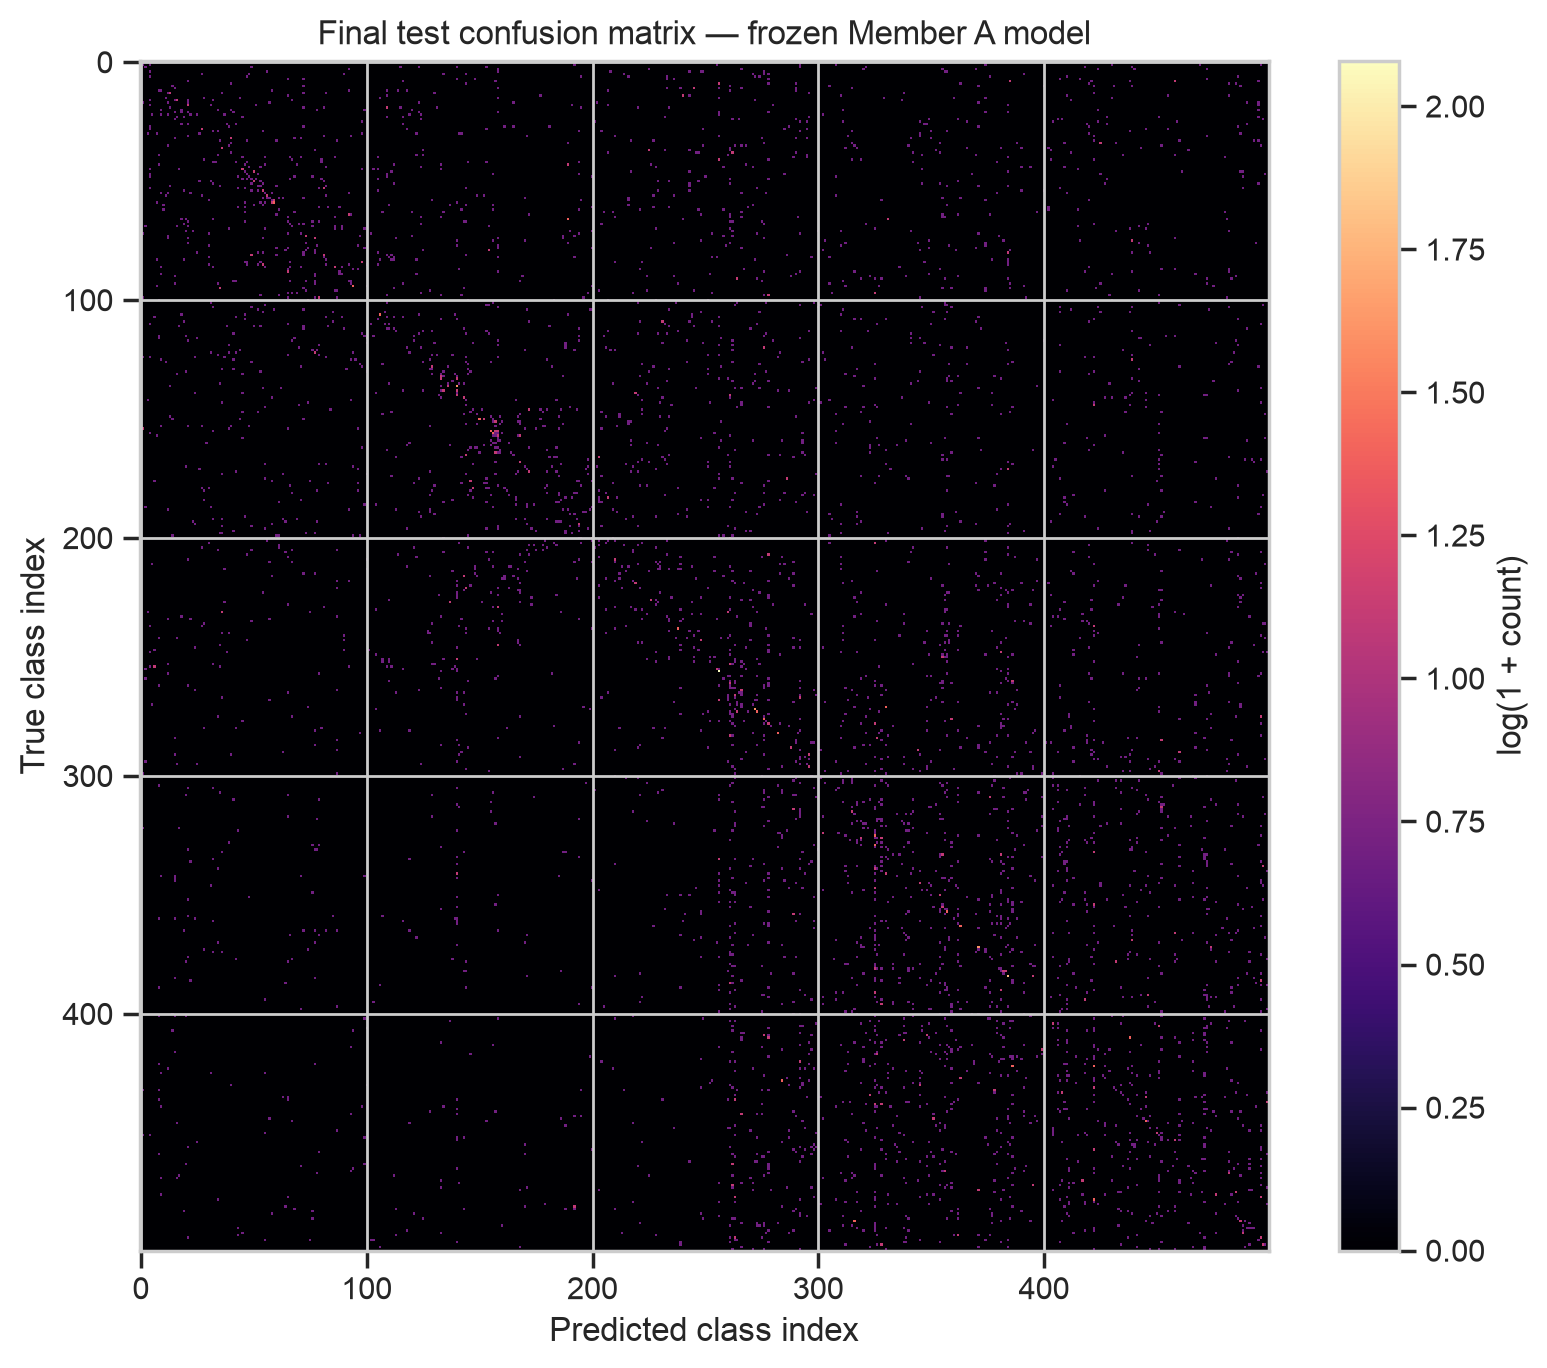

In [2]:
from pathlib import Path
from IPython.display import Image, display

relative_image_path = Path(
    "experiment_workspace/results/"
    "final_test_combined_128_c1/"
    "test_confusion_matrix.png"
)

candidate_paths = [
    Path.cwd() / relative_image_path,
    Path.cwd().parent / relative_image_path,
    Path.cwd() / "9517GroupProject" / relative_image_path,
]

confusion_matrix_path = next(
    (path.resolve() for path in candidate_paths if path.exists()),
    None,
)

assert confusion_matrix_path is not None, (
    "Confusion matrix image not found.\n"
    f"Current working directory: {Path.cwd()}\n"
    "Checked paths:\n"
    + "\n".join(str(path.resolve()) for path in candidate_paths)
)

print(f"Displaying saved image: {confusion_matrix_path}")
display(Image(filename=str(confusion_matrix_path)))

**## 16. Member A Decision Log**

| Date | Experimental Question | Decision | Validation Evidence | Status |
|---|---|---|---|---|
| 2026-07-22 | Did all pilot experiments pass? | The Colour/LBP/HOG/Combined pipelines all passed | All four descriptors completed 20-class training, validation, and result saving | Completed |
| 2026-07-23 | 128 or 224? | Selected 128 | Top-1: 2.84% vs 2.32%; Macro F1: 2.48% vs 2.08%; training was approximately three times faster; paired p=0.033 | Completed |
| 2026-07-23 | Best descriptor? | Combined | Top-1: 4.80%; Top-5: 12.54%; Macro F1: 4.25%; significantly better than HOG, paired p<1.8e-14 | Completed |
| 2026-07-23 | Best C? | C=1 | Top-1: 4.80%; Top-5: 12.54%; Macro F1: 4.25%; significantly better than C=10, paired p=0.0012 | Completed |
| 2026-07-23 | Freeze the final model? | Frozen: 128×128 + Combined + C=1 | Top-1: 4.80%; Top-5: 12.54%; Macro F1: 4.25%; all validation ablations completed | Completed |
| 2026-07-23 | Unlock the test set? | Relocked after the single final evaluation | Test Top-1: 4.48%; Top-5: 12.16%; Macro F1: 3.99% | `CONSUMED_LOCKED` |